In [1]:
import sys, os, warnings
import numpy as np
import scipy as sp
import pandas as pd
import nibabel as nib
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from brainsmash.mapgen.base import Base

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])
sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/nctpy/src'])

from src.plotting import plot_repeated_measures_violins, plot_subject_level_violins
from src.notebook import load_notebook_data

from src.timescales import create_ints_dataframe_custom_grouping, convert_data_dict, average_data_dict_converted
from snaplab_tools.plotting.plotting import plot_correlation, plot_correlation_unity, plot_brain_surface_data
from snaplab_tools.plotting.utils import get_my_colors
from snaplab_tools.utils import winsorize

In [2]:
def function_helper(data_dict_centiles):
    df_plot = pd.DataFrame()
    for c, condition in enumerate(data_dict_centiles.keys()):
        print(condition)
        df_tmp_1 = pd.DataFrame()
        n_subs_tmp = data_dict_centiles[condition].shape[0]
        for i in np.arange(n_subs_tmp):
            df_tmp_2 = pd.DataFrame()
            df_tmp_2['subject'] = np.zeros(10) + i
            df_tmp_2[condition] = data_dict_centiles[condition][i, :]
            df_tmp_1 = pd.concat((df_tmp_1, df_tmp_2), axis=0)
        if c == 0:
            df_plot['subject'] = df_tmp_1['subject']
        df_plot[condition] = df_tmp_1[condition]
        
    return df_plot

def simple_stat_plot(df_ints, df_centiles, ax, stat='std'):
    df_plot = pd.DataFrame(columns=df_centiles.columns)
    for subj in df_centiles['subject'].unique():
        df_plot.loc[subj, :] = df_centiles.loc[df_centiles['subject'] == subj, :].mean()
    df_plot.drop(labels=['subject',], inplace=True, axis=1)
    if stat == 'std':
        x = df_ints.std()
        y = df_plot[df_ints.columns].std()
        label = 'Stand. Dev.'
    elif stat == 'var':
        x = df_ints.var()
        y = df_plot[df_ints.columns].var()
        label = 'Variance'
    elif stat == 'range':
        x = df_ints.max() - df_ints.min()
        y = df_plot[df_ints.columns].max() - df_plot[df_ints.columns].min()
        label = 'Range'

    ax.plot(x, linewidth=1, marker='.', linestyle='dashed', markersize=4, color="#66c2a5", label='Region')
    ax.plot(y, linewidth=1, marker='.', linestyle='dashed', markersize=4, color="#fc8d62", label='Subject')
    # ax.legend()
    ax.set_ylabel(label)

# Load data

In [3]:
dataset = 'HCP-YA'
which_modality = 'FMRI'
meg_freq = '_lp-0.5hz'
use_7t = True
output_type = 'timescale_zero_crossing_robust_nc3'
notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   use_7t=use_7t, output_type=output_type)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
Raw data directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
Derivatives data directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
timescale_zero_crossing_robust_nc3


Loading timescale_zero_crossing_robust_nc3: 100%|██████████| 4238/4238 [00:00<00:00, 9092.43it/s]


4238


Loading timescale_zero_crossing_robust_nc3_resids: 100%|██████████| 4238/4238 [00:00<00:00, 9414.48it/s]


4238
Number of subjects: 163
Loading connectivity data...
	sub-380036 not found
	sub-971160 not found
Loading myelin data...


In [4]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
results_dir = notebook_data['results_dir']

dict_neuro = notebook_data['supporting_data']['dict_neuro']
distance_matrix = notebook_data['supporting_data']['distance_matrix']
gene_expression_nanmask = notebook_data['supporting_data']['gene_expression_nanmask']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

print(data_dict.keys())
print(dict_neuro.keys())

dict_keys(['sub-100610_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIGAMBLINGRL_space-fsLR

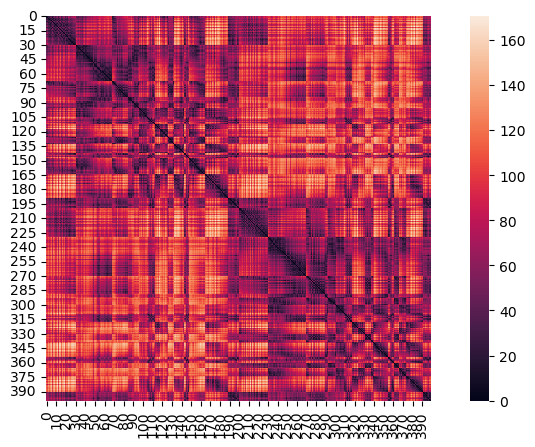

In [5]:
f, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))
sns.heatmap(distance_matrix, ax=ax, square=True)
plt.show()

In [6]:
timescales_processor.scan_registry.head()

,scan_string,sub,task,space,seg,ses,modality,tr,condition
0,sub-100610_task-rfMRIREST1LR_space-fsLR_seg-Sc...,100610,rfMRIREST1LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
1,sub-100610_task-rfMRIREST1RL_space-fsLR_seg-Sc...,100610,rfMRIREST1RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
2,sub-100610_task-rfMRIREST2LR_space-fsLR_seg-Sc...,100610,rfMRIREST2LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
3,sub-100610_task-rfMRIREST2RL_space-fsLR_seg-Sc...,100610,rfMRIREST2RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
4,sub-100610_task-tfMRIWMLR_space-fsLR_seg-Schae...,100610,tfMRIWMLR,fsLR,Schaefer4007,1,MRI3T,0.72,task


In [7]:
subject_ids = timescales_processor.scan_registry['sub'].unique()
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 163


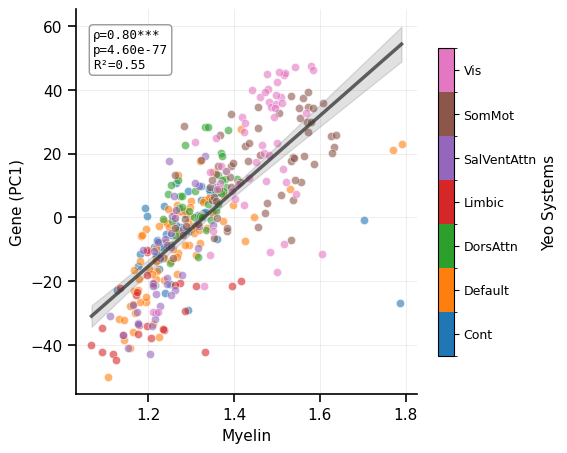

In [8]:
if dataset == 'HCP-YA':
    fig, axes = plt.subplots(nrows=1, ncols=1, sharex=False, sharey=False, figsize=(5.5, 5))
    plot_correlation(dict_neuro['Myelin'][gene_expression_nanmask], dict_neuro['Gene (PC1)'][gene_expression_nanmask], axes,
                    data_group=np.asarray(yeo_systems)[gene_expression_nanmask], show_stats=True, fontsize=11, method='spearman',
                    size=35, x_label='Myelin', y_label='Gene (PC1)', cbar_label='Yeo Systems',
                    auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')

# BrainSMASH null

In [9]:
if dataset == 'HCP-YA':
    neuro_cols = ['Myelin', 'Gene (PC1)', 'Strength']
    # neuro_cols = ['Gene (PC1)', 'Myelin', 'Strength', 'Gene_EI_ratio']
    # neuro_cols = ['Gene (PC1)', 'Myelin', 'SC_Degree']
    # neuro_cols = ['Gene_PVALB', 'Gene_GRIA1', 'Gene_GRIN2A', 'Gene_GABRA1', 'Gene_GABRA3']
    # neuro_cols = ['Gene_GABRA1', 'Gene_GABRA2', 'Gene_GABRA3', 'Gene_GABRA4', 'Gene_GABRA5']
else:
    neuro_cols = ['Gene (PC1)']

In [10]:
n_permutations = 10000
# n_permutations = 100

brain_map_surrogates = dict()
for neuro_str in neuro_cols:
    out_file = os.path.join(timescales_processor.output_dir, 'data', 'brain_map_surrogates_{0}.npy'.format(neuro_str.replace(' ', '_')))
    if os.path.exists(out_file):
        print(f'Loading {neuro_str}')
        brain_map_surrogates[neuro_str] = np.load(out_file)
    else:
        print(f'Running {neuro_str}')
        base = Base(x=dict_neuro[neuro_str], D=distance_matrix)
        brain_map_surrogates[neuro_str] = base(n=n_permutations)

        np.save(out_file, brain_map_surrogates[neuro_str])
        
    print(neuro_str, brain_map_surrogates[neuro_str].shape)

Loading Myelin
Myelin (10000, 400)
Loading Gene (PC1)
Gene (PC1) (10000, 400)
Loading Strength
Strength (10000, 400)


# Data for figures

In [11]:
collapse_hcp = True
sort_by_median = True

if which_modality == 'FMRI' and 'HCP' in dataset:
    if collapse_hcp:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        average_all_rest=True, average_7t_movies=True,
                                                        average_3t_tasks=True)
        if dataset == 'HCP-YA' and use_7t:
            custom_order = ['Rest', 'Movies', 'Tasks']
            df_ints = df_ints[custom_order]
        elif dataset == 'HCP-YA' and not use_7t:
            custom_order = ['Rest', 'Tasks']
            df_ints = df_ints[custom_order]
    else:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        average_7t_rest=True, average_3t_rest=True,
                                                        average_3t_task_pairs=True, average_7t_movies=True)
elif which_modality == 'MEG' and 'HCP' in dataset:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                    average_meg_rest=True, average_meg_task=True)
else:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median)

# if dataset == 'HCP-YA':
    # df_ints = df_ints[['task-REST7T', 'task-REST3T', 'task-MOVIE', 'task-tfMRIWM']]
    
data_dict_centiles = convert_data_dict(data_dict, timescales_processor.scan_registry, brain_map=dict_neuro['SA_Axis'])
if which_modality == 'FMRI' and 'HCP' in dataset:
    if collapse_hcp:
        data_dict_centiles = average_data_dict_converted(data_dict_centiles, average_3t_tasks=True, average_7t_movies=True, average_all_rest=True)
        data_dict_centiles = {key: data_dict_centiles[key] for key in custom_order if key in data_dict_centiles}
    else:
        data_dict_centiles = average_data_dict_converted(data_dict_centiles, 
                                                         average_7t_rest=True, average_3t_rest=True,
                                                         average_3t_task_pairs=True, average_7t_movies=True)
elif which_modality == 'MEG' and 'HCP' in dataset:
    data_dict_centiles = average_data_dict_converted(data_dict_centiles,
                                                     average_meg_rest=True, average_meg_task=True)

Scan: task-rfMRIREST1LR
  Number of subjects: 163
  Mean INT range: [4.341, 14.482]
Scan: task-rfMRIREST1RL
  Number of subjects: 163
  Mean INT range: [4.321, 15.600]
Scan: task-rfMRIREST2LR
  Number of subjects: 163
  Mean INT range: [4.709, 16.856]
Scan: task-rfMRIREST2RL
  Number of subjects: 163
  Mean INT range: [4.693, 15.356]
Scan: task-tfMRIWMLR
  Number of subjects: 163
  Mean INT range: [2.976, 6.711]
Scan: task-tfMRIWMRL
  Number of subjects: 163
  Mean INT range: [2.912, 6.604]
Scan: task-tfMRIEMOTIONLR
  Number of subjects: 163
  Mean INT range: [3.516, 8.055]
Scan: task-tfMRIEMOTIONRL
  Number of subjects: 163
  Mean INT range: [3.534, 8.360]
Scan: task-tfMRIGAMBLINGLR
  Number of subjects: 163
  Mean INT range: [3.472, 8.291]
Scan: task-tfMRIGAMBLINGRL
  Number of subjects: 163
  Mean INT range: [3.593, 8.477]
Scan: task-tfMRILANGUAGELR
  Number of subjects: 163
  Mean INT range: [4.152, 11.454]
Scan: task-tfMRILANGUAGERL
  Number of subjects: 163
  Mean INT range: [4.0

# Prefigures

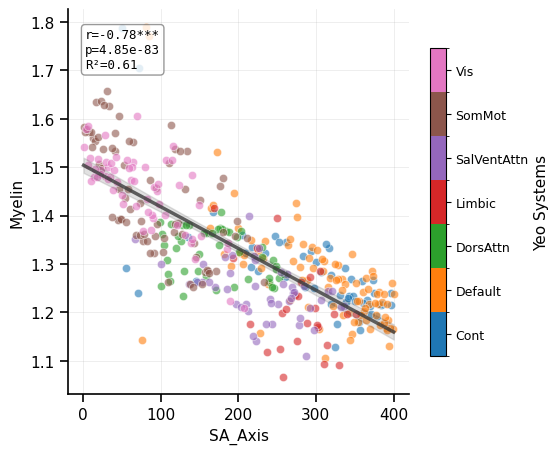

In [12]:
if dataset == 'HCP-YA':
    fig, axes = plt.subplots(nrows=1, ncols=1, sharex=False, sharey=False, figsize=(5.5, 5))
    plot_correlation(dict_neuro['SA_Axis'], dict_neuro['Myelin'], axes,
                    data_group=np.asarray(yeo_systems), show_stats=True, fontsize=11, method='pearson',
                    size=35, x_label='SA_Axis', y_label='Myelin', cbar_label='Yeo Systems',
                    auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')
    fig.savefig(os.path.join(results_dir, 'sa_myelin_corr.png'), bbox_inches='tight', dpi=300, transparent=True)

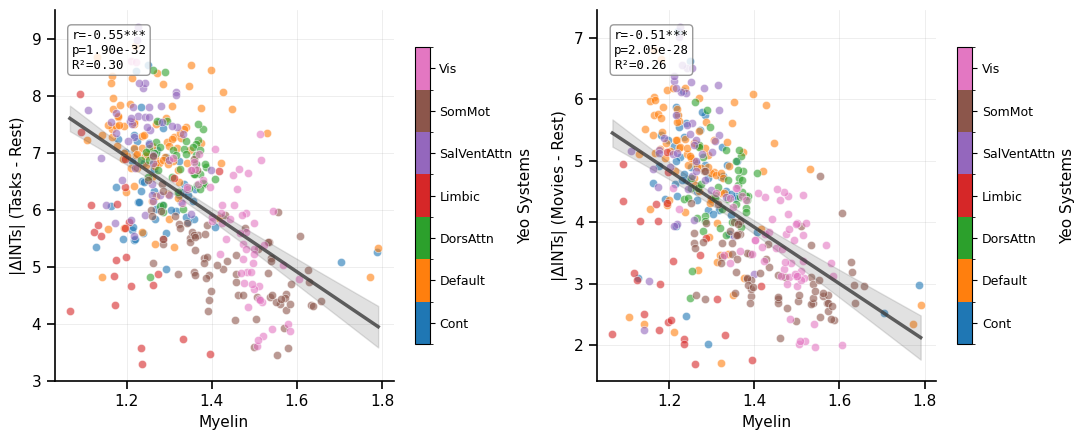

In [13]:
if dataset == 'HCP-YA':
    fig, axes = plt.subplots(nrows=1, ncols=2, sharex=False, sharey=False, figsize=(11, 4.5))
    plot_correlation(dict_neuro['Myelin'], np.abs(df_ints['Tasks'] - df_ints['Rest']), axes[0],
                    data_group=np.asarray(yeo_systems), show_stats=True, fontsize=11, method='pearson',
                    size=35, x_label='Myelin', y_label='|ΔINTs| (Tasks - Rest)', cbar_label='Yeo Systems',
                    auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')

    plot_correlation(dict_neuro['Myelin'], np.abs(df_ints['Movies'] - df_ints['Rest']), axes[1],
                    data_group=np.asarray(yeo_systems), show_stats=True, fontsize=11, method='pearson',
                    size=35, x_label='Myelin', y_label='|ΔINTs| (Movies - Rest)', cbar_label='Yeo Systems',
                    auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')
    
    fig.tight_layout()
    fig.savefig(os.path.join(results_dir, 'myelin_INT_deflection_corr.png'), bbox_inches='tight', dpi=300, transparent=True)

In [14]:
df_ints

,Rest,Movies,Tasks
0,11.660879,8.193763,5.545557
1,13.640941,9.077710,5.024961
2,12.105358,8.398773,6.233059
3,11.837853,8.307260,5.383067
4,11.863497,7.816462,6.021455
...,...,...,...
395,14.029458,8.415133,5.855811
396,12.650741,7.733129,5.830990
397,11.031227,7.685583,5.680596
398,13.228558,8.512781,5.886310


# Figure 1: Modulation of INTs vs SA axis

### Plot timescales brain plot (average)

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/mnt/storage_ssd_raid/research_projects/snaplab_tools/snaplab_tools/plotting/plotting.py:1070: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


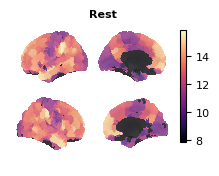

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/mnt/storage_ssd_raid/research_projects/snaplab_tools/snaplab_tools/plotting/plotting.py:1070: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


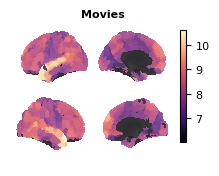

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/mnt/storage_ssd_raid/research_projects/snaplab_tools/snaplab_tools/plotting/plotting.py:1070: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


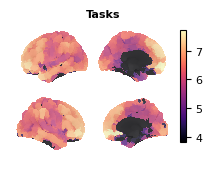

In [15]:
if dataset == 'HCP-YA':
    for column in df_ints.columns:
        fig, axes = plot_brain_surface_data(
            data_vector=df_ints[column],
            parcellation='schaefer_400',
            cmap='magma',
            symmetric_cbar=False,
            title=column, figsize=(2.1, 1.6), fontsize=8, cbar_label=None
        )
        plt.show()
        fig.savefig(os.path.join(results_dir, f'timescales_brain_{column}.png'), bbox_inches='tight', dpi=300, transparent=True)

### Plot timescales, average (regional) & subject-level (SA centiles)

Data shape: (400, 3)
Conditions: ['Rest', 'Movies', 'Tasks']


/tmp/ipykernel_1657671/2232279679.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([''])


Rest
Movies
Tasks
Number of subjects: 163
Selected regions: [0 1 2 3 4 5 6 7 8 9]
Conditions: ['Rest', 'Movies', 'Tasks']
Filtered data shape: (1630, 5)
Expected rows: 1630
Sorted conditions by median (descending):
  Rest: median = 12.4450
  Movies: median = 8.2333
  Tasks: median = 6.1605
Fitting polynomial trends to distribution means...
  Rest: Best fit = Quadratic (R² = 0.946)
  Movies: Best fit = Quadratic (R² = 0.811)
  Tasks: Best fit = Quadratic (R² = 0.901)


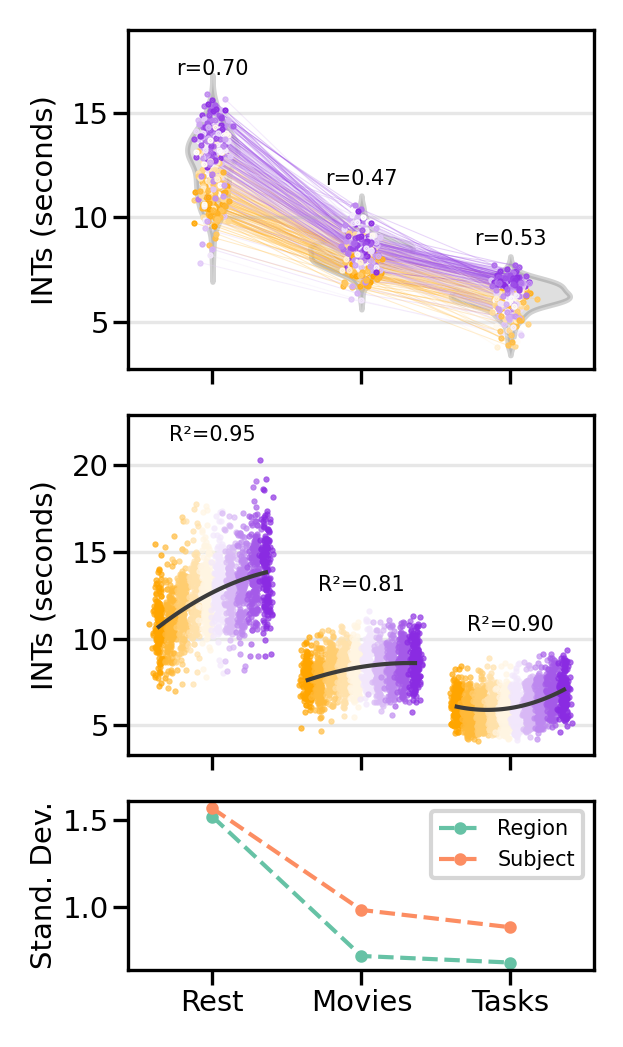

In [16]:
plt.rcParams.update({'font.size': 7})
if 'B' in output_type:
    ylabel_text = 'INTs (B)'
else:
    ylabel_text = 'INTs (seconds)'

fig, axes = plt.subplots(nrows=3, ncols=1, sharex=True, sharey=False,
                         figsize=(len(df_ints.columns)*.7, 3.5), 
                         dpi=300, gridspec_kw={'height_ratios':[2, 2, 1]})
axes[0] = plot_repeated_measures_violins(df_ints, axes[0], color_vector=dict_neuro['SA_Axis'], colormap='sydnor_sa', add_colorbar=False,
                                         point_alpha=1, line_alpha=0.3, point_size=0.25, line_width=0.25, violin_alpha=0.25,
                                         correlation_method='spearman')
axes[0].set_xticklabels([''])
axes[0].set_xlabel('')

df_centiles = function_helper(data_dict_centiles)
if dataset == 'WAND':
    df_centiles['reversallearning'] = winsorize(df_centiles['reversallearning'])
axes[1], trend_results = plot_subject_level_violins(df_centiles, axes[1], np.arange(10),
                                                    point_alpha=0.75, point_size=0.25,
                                                    show_violins=False, show_lines=False, fit_trends=True, show_r2_annotation=True,
                                                    hide_legend=True, sort_by_median=sort_by_median)
axes[1].set_xlabel('')

try:
    simple_stat_plot(df_ints, df_centiles, axes[2], stat='std')
except:
    pass

if dataset == 'HCP-YA':
    axes[0].set_ylabel(ylabel_text, fontsize=7)
    axes[1].set_ylabel(ylabel_text, fontsize=7)
    axes[2].legend(fontsize=5)
else:
    axes[0].set_ylabel('')
    axes[1].set_ylabel('')
    axes[2].set_ylabel('')

for ax in axes:
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)
    if 'B' in output_type:
        ax.yaxis.set_label_coords(-0.35, 0.5)
    else:
        ax.yaxis.set_label_coords(-0.15, 0.5)

plt.tight_layout()
if which_modality == 'MEG':
    file_label = f'{output_type}_MEG{meg_freq}.png'
else:
    file_label = f'{output_type}.png'
fig.savefig(os.path.join(results_dir, file_label), bbox_inches='tight', dpi=300, transparent=True)
plt.show()

# Figure 2: Whole-brain spatial correlation analysis

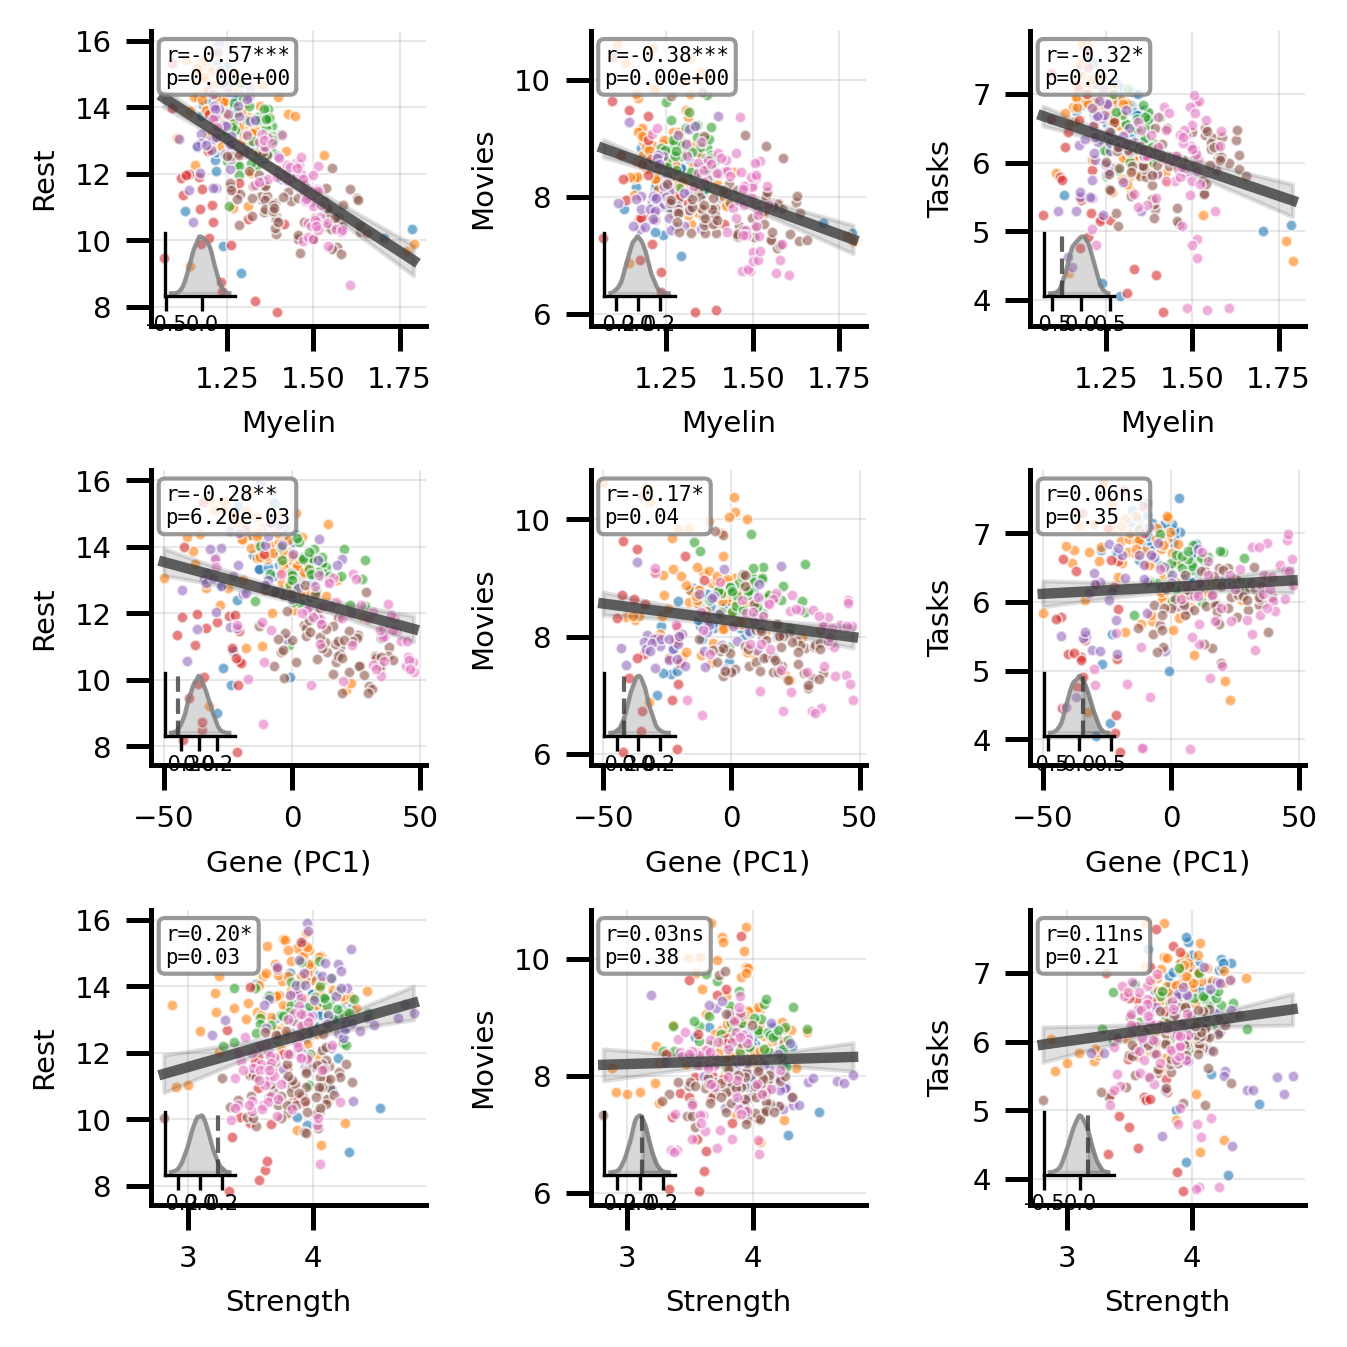

In [17]:
if dataset == 'HCP-YA':
    fig, axes = plt.subplots(nrows=len(neuro_cols), ncols=len(df_ints.columns), sharex=False, sharey=False, figsize=(1.5*len(df_ints.columns), 4.5), dpi=300)
    row_counter = 0

    for neuro_str in neuro_cols:
        col_counter = 0
        for int_str in df_ints.columns:
            if 'Gene' in neuro_str:
                x = dict_neuro[neuro_str][gene_expression_nanmask]
                y = df_ints.loc[gene_expression_nanmask, int_str]
                data_group = np.asarray(yeo_systems)[gene_expression_nanmask]
                brain_map_surr = brain_map_surrogates[neuro_str][:, gene_expression_nanmask]
            else:
                x = dict_neuro[neuro_str]
                y = df_ints.loc[:, int_str]
                data_group = yeo_systems
                brain_map_surr = brain_map_surrogates[neuro_str]

            null_distribution = np.zeros(n_permutations)
            for i in np.arange(n_permutations):
                null_distribution[i] = sp.stats.spearmanr(brain_map_surr[i], y)[0]

            plot_correlation(x, y, axes[row_counter, col_counter],
                            data_group=data_group, show_stats=True, fontsize=7, method='pearson',
                            size=7, x_label=neuro_str, y_label=int_str, cbar_label='Yeo Systems', show_colorbar=False,
                            custom_inset={'custom_null': null_distribution})
            col_counter += 1
        row_counter += 1

    plt.tight_layout()
    fig.savefig(os.path.join(results_dir, 'neuroanatomy_INTs_correlations.png'), bbox_inches='tight', dpi=300, transparent=True)
    plt.show()